In [ ]:
pip install pandas numpy scikit-learn shap lime kagglehub matplotlib seaborn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 5.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=55cb8bbef5a9a021b64addd0ffb08aeacaca7aed382839f7f016f9dc3d7cfef6
  Stored in directory: /root/.cache/pip/wheels/85/fa/a3/9c2d44c9f3cd77cf4e533b58900b2bf4487f2a17e8ec212a3d
Successfully built lime


In [ ]:
import kagglehub
import pandas as pd

# Download the dataset
path = kagglehub.dataset_download("nancyalaswad90/breast-cancer-dataset")
print("Dataset path:", path)

# Load the dataset (assuming CSV files are inside)
data = pd.read_csv(f"{path}/data.csv")  # Adjust filename if needed
data.head()

Dataset path: /kaggle/input/breast-cancer-dataset


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

# Drop 'id' column
data = data.drop(columns=['id'])

# Encode 'diagnosis': M -> 1, B -> 0
le = LabelEncoder()
data['diagnosis'] = le.fit_transform(data['diagnosis'])

# Split into features and target
X = data.drop('diagnosis', axis=1)
y = data['diagnosis']

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Split into training and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

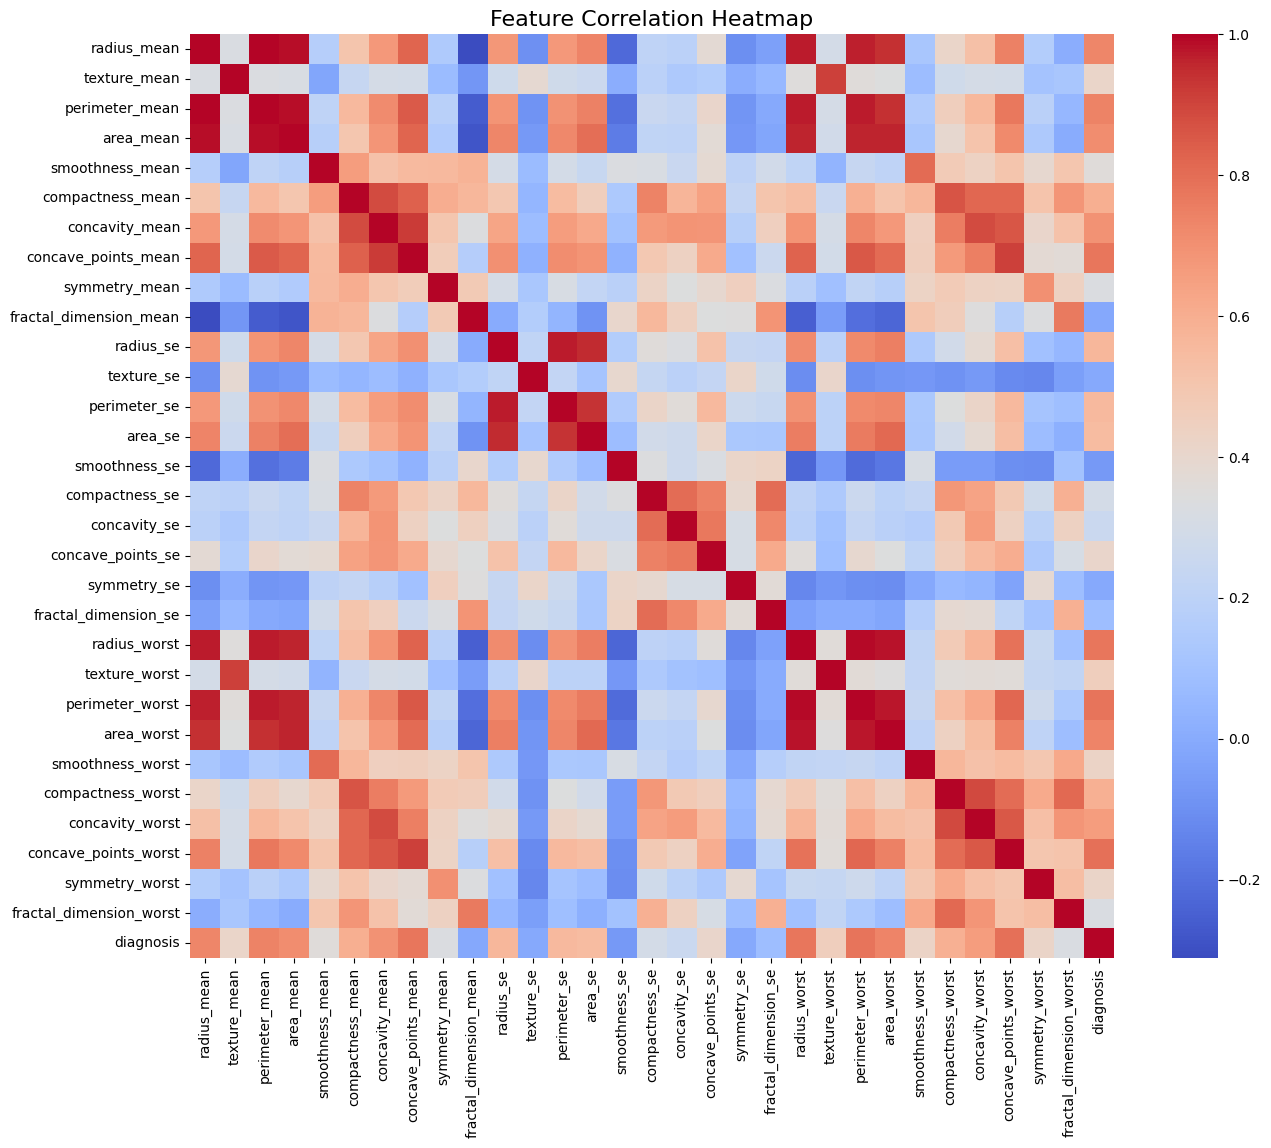

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Assuming X_scaled, X, and y are already defined
X_df = pd.DataFrame(X_scaled, columns=X.columns)
X_df['diagnosis'] = y.values

# Plot correlation heatmap
plt.figure(figsize=(15, 12))
sns.heatmap(X_df.corr(), cmap='coolwarm', annot=False, fmt='.2f', square=True)
plt.title("Feature Correlation Heatmap", fontsize=16)

# Save the figure BEFORE showing
plt.savefig('correlation_heatmap.jpg', dpi=300, bbox_inches='tight')  # Better quality
plt.show()

<ipython-input-8-eff8ad8a5cd6>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='diagnosis', data=data, palette='Set2')


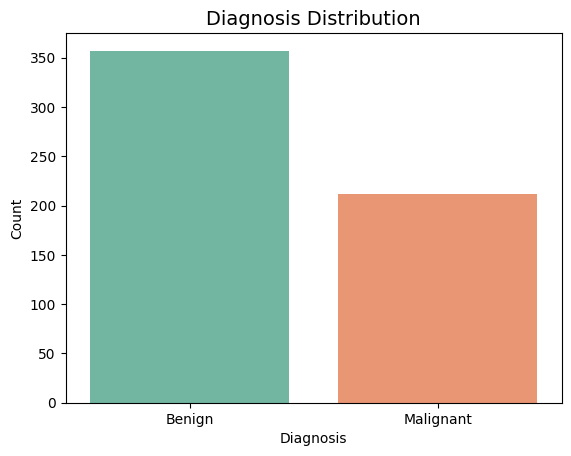

In [ ]:
#Diagnosis Distribution – Check class imbalance
# Visualize the count of Benign (0) vs Malignant (1) cases
sns.countplot(x='diagnosis', data=data, palette='Set2')
plt.title("Diagnosis Distribution", fontsize=14)
plt.xticks([0, 1], ['Benign', 'Malignant'])
plt.ylabel("Count")
plt.xlabel("Diagnosis")
plt.savefig('diagnosis_dist.jpg', dpi=300, bbox_inches='tight')
plt.show()


🔍 Evaluating: Random Forest


/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
540 fits failed out of a total of 1080.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
331 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/usr/local/lib/python3.11/dist-packages/sklearn/base.py", line 1382, in wrapper
    estimator._validate_params()
  File "/usr/local/lib/python3.11/dist-packages/sklearn/base.py", line 436, in _validate_params
    validate_parameter_constraints(
  File "/usr/local/lib/python3.11/dist-packages/sklearn/uti

✅ Test Accuracy: 0.9649122807017544

📋 Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.99      0.97        71
           1       0.98      0.93      0.95        43

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



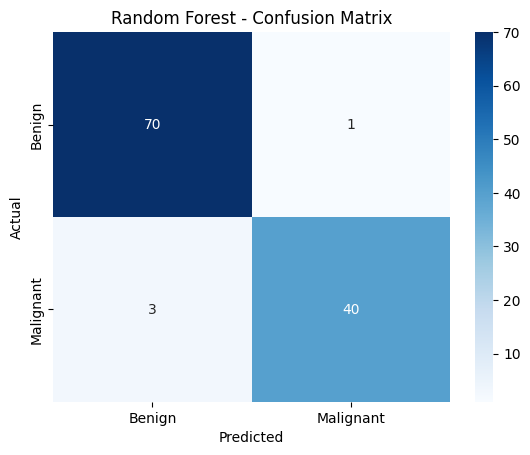

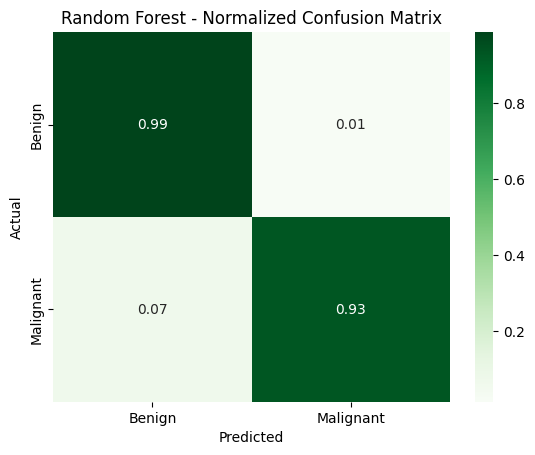

Best Hyperparameters: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}

🔍 Evaluating: XGBoost


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [04:46:11] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


✅ Test Accuracy: 0.956140350877193

📋 Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.97      0.97        71
           1       0.95      0.93      0.94        43

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



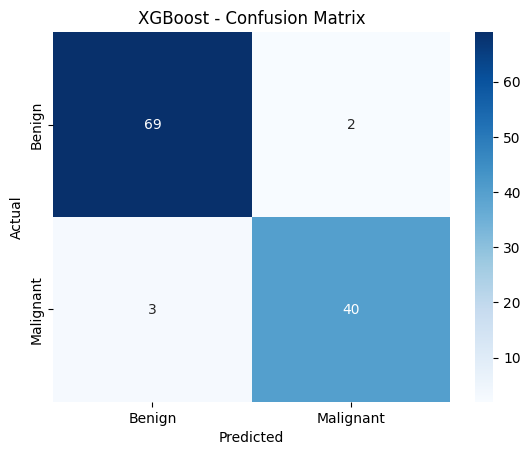

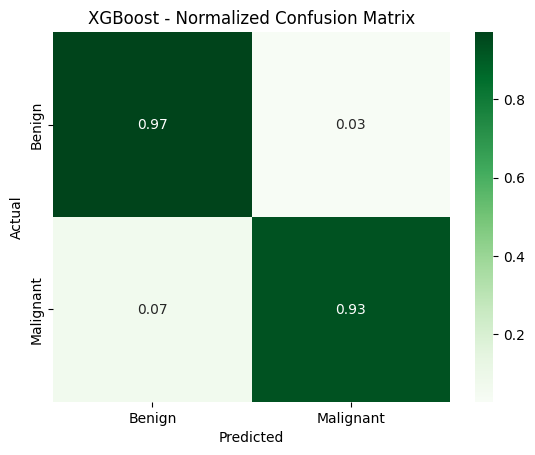

Best Hyperparameters: {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 100, 'subsample': 0.9}

🔍 Evaluating: Logistic Regression
✅ Test Accuracy: 0.9824561403508771

📋 Classification Report:
               precision    recall  f1-score   support

           0       0.97      1.00      0.99        71
           1       1.00      0.95      0.98        43

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


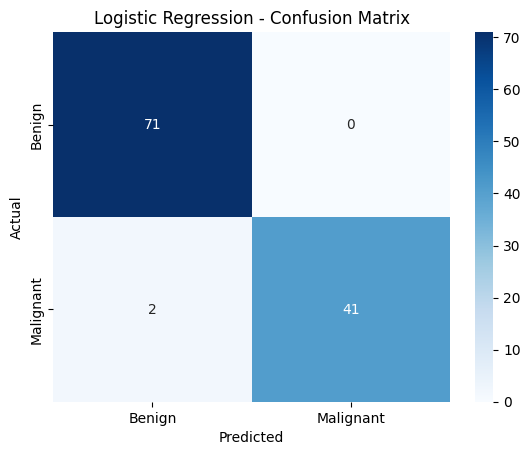

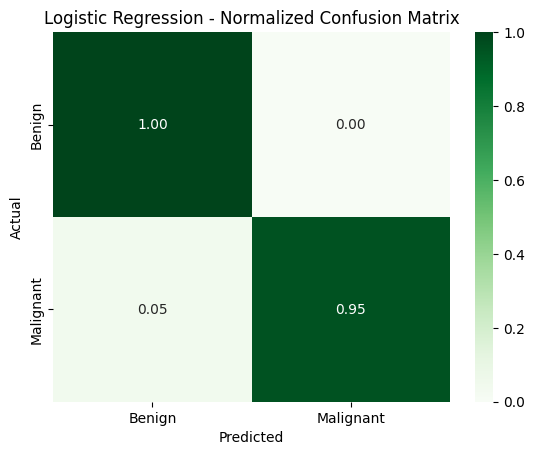

Best Hyperparameters: {'C': 0.1, 'penalty': 'l2', 'solver': 'saga'}

🔍 Evaluating: SVM
✅ Test Accuracy: 0.9736842105263158

📋 Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.99      0.98        71
           1       0.98      0.95      0.96        43

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



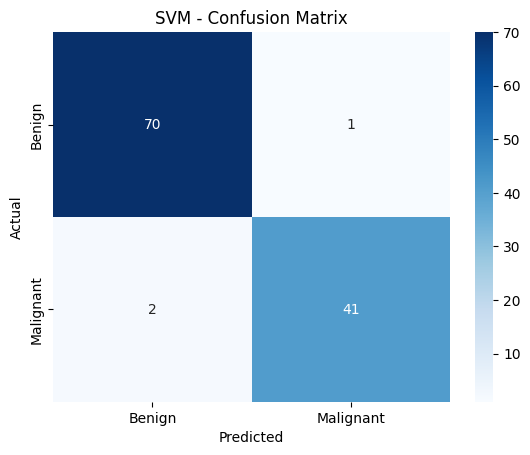

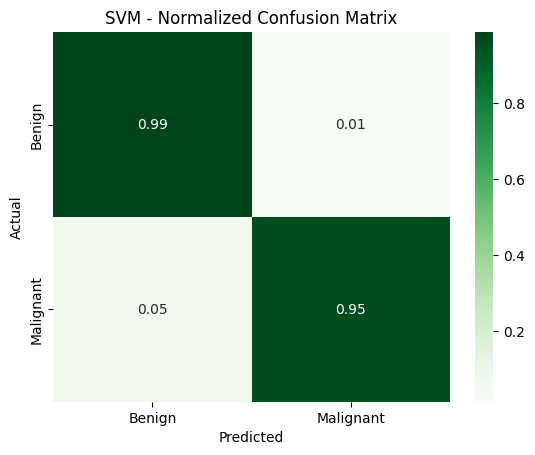

Best Hyperparameters: {'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}

🔍 Evaluating: KNN
✅ Test Accuracy: 0.9473684210526315

📋 Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.96      0.96        71
           1       0.93      0.93      0.93        43

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



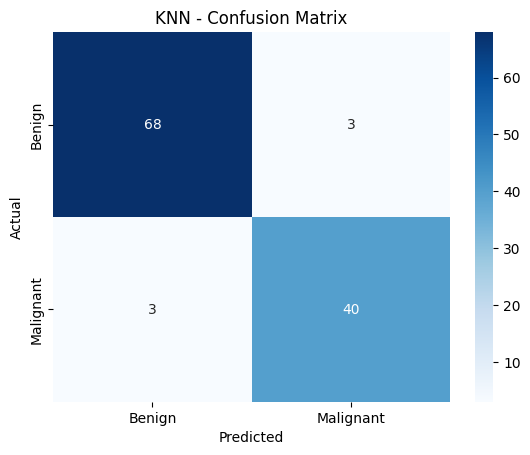

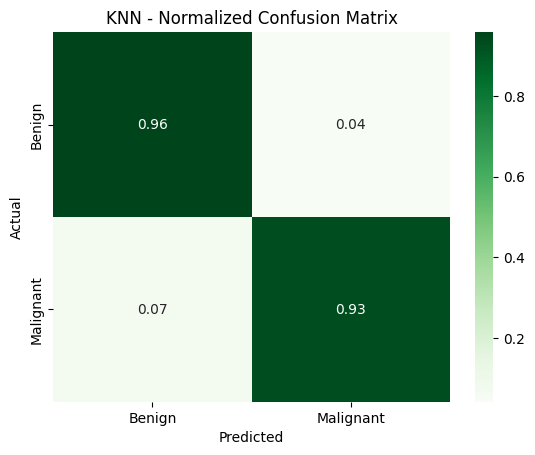

Best Hyperparameters: {}

🔍 Evaluating: Neural Network (MLP)
✅ Test Accuracy: 0.9649122807017544

📋 Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.97      0.97        71
           1       0.95      0.95      0.95        43

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114



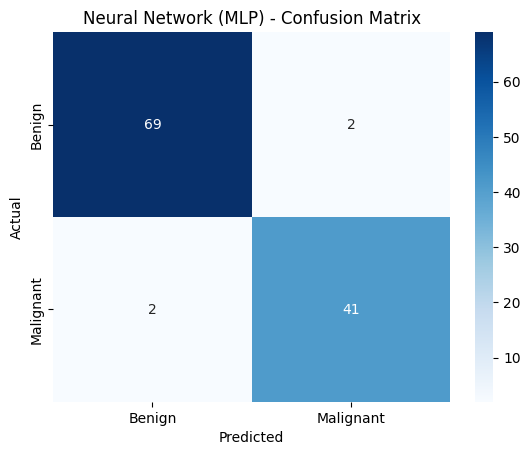

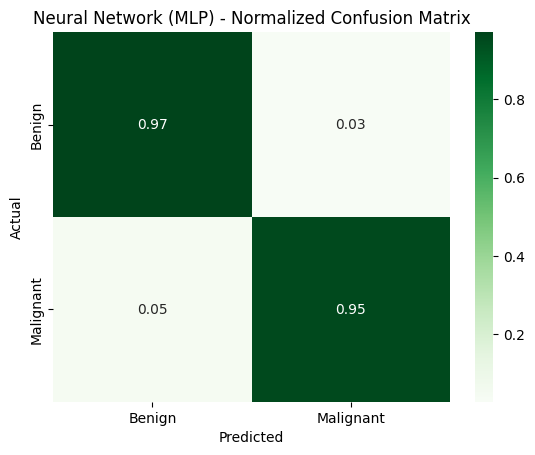

Best Hyperparameters: {'activation': 'relu', 'hidden_layer_sizes': (100,), 'solver': 'adam'}


In [ ]:
import os
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import pandas as pd
import numpy as np

# Ensure the directory to save images exists
output_dir = 'model_results_images'
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

# Define models
models = {
    "Random Forest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42),
    "Logistic Regression": LogisticRegression(),
    "SVM": SVC(probability=True),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Neural Network (MLP)": MLPClassifier(hidden_layer_sizes=(100,), max_iter=1000, random_state=42)
}

# Hyperparameter tuning for Random Forest
rf_params = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['auto', 'sqrt']
}

# Hyperparameter tuning for XGBoost
xgb_params = {
    'n_estimators': [100, 200],
    'max_depth': [3, 6, 9],
    'learning_rate': [0.01, 0.1, 0.3],
    'subsample': [0.8, 0.9, 1.0]
}

# Hyperparameter tuning for Logistic Regression
lr_params = {
    'C': [0.1, 1, 10],
    'penalty': ['l2'],
    'solver': ['liblinear', 'saga']
}

# Hyperparameter tuning for SVM
svm_params = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}

# Hyperparameter tuning for Neural Network (MLP)
mlp_params = {
    'hidden_layer_sizes': [(50,), (100,), (150,)],
    'activation': ['relu', 'tanh'],
    'solver': ['adam', 'sgd']
}

# Define StratifiedKFold Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Evaluate each model with cross-validation and hyperparameter tuning
for name, model in models.items():
    print(f"\n🔍 Evaluating: {name}")

    # Select the hyperparameter grid based on the model
    if name == "Random Forest":
        grid_search = GridSearchCV(model, rf_params, cv=cv, scoring='accuracy', n_jobs=-1)
    elif name == "XGBoost":
        grid_search = GridSearchCV(model, xgb_params, cv=cv, scoring='accuracy', n_jobs=-1)
    elif name == "Logistic Regression":
        grid_search = GridSearchCV(model, lr_params, cv=cv, scoring='accuracy', n_jobs=-1)
    elif name == "SVM":
        grid_search = GridSearchCV(model, svm_params, cv=cv, scoring='accuracy', n_jobs=-1)
    elif name == "Neural Network (MLP)":
        grid_search = GridSearchCV(model, mlp_params, cv=cv, scoring='accuracy', n_jobs=-1)
    else:
        grid_search = GridSearchCV(model, {}, cv=cv, scoring='accuracy', n_jobs=-1)

    # Fit model using GridSearchCV
    grid_search.fit(X_train, y_train)

    # Best model found by GridSearchCV
    best_model = grid_search.best_estimator_
    y_pred = best_model.predict(X_test)

    # Accuracy
    print("✅ Test Accuracy:", accuracy_score(y_test, y_pred))

    # Precision, Recall, F1
    print("\n📋 Classification Report:\n", classification_report(y_test, y_pred))

    # Confusion Matrix (Regular)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Benign', 'Malignant'], yticklabels=['Benign', 'Malignant'])
    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.savefig(os.path.join(output_dir, f"{name}_confusion_matrix.png"))  # Save the image
    plt.show()

    # Normalized Confusion Matrix
    cm_norm = confusion_matrix(y_test, y_pred, normalize='true')
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Greens', xticklabels=['Benign', 'Malignant'], yticklabels=['Benign', 'Malignant'])
    plt.title(f"{name} - Normalized Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.savefig(os.path.join(output_dir, f"{name}_normalized_confusion_matrix.png"))  # Save the image
    plt.show()

    print(f"Best Hyperparameters: {grid_search.best_params_}")

In [ ]:
pip install shap lime

In [ ]:
import shap

# Step 1: Train your best model (Logistic Regression)
from sklearn.linear_model import LogisticRegression
best_model = LogisticRegression(max_iter=1000)
best_model.fit(X_train, y_train)

# Step 2: Create SHAP explainer for linear model
explainer = shap.LinearExplainer(best_model, X_train, feature_perturbation="interventional")

# Step 3: Compute SHAP values for the test set
shap_values = explainer.shap_values(X_test)

/usr/local/lib/python3.11/dist-packages/shap/explainers/_linear.py:99: FutureWarning: The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, maskers.Partition or maskers.Impute).
  warnings.warn(wmsg, FutureWarning)


In [ ]:
print(X.columns)

Index(['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean',
       'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave_points_worst',
       'symmetry_worst', 'fractal_dimension_worst'],
      dtype='object')


In [ ]:
import shap
import matplotlib.pyplot as plt
import os

# Create a directory to save SHAP plots
shap_dir = 'shap_plots'
if not os.path.exists(shap_dir):
    os.makedirs(shap_dir)

# 1. SHAP Summary Plot for all features
plt.figure()
shap.summary_plot(shap_values, X_test, feature_names=X.columns, show=False)
plt.title('SHAP Summary Plot')
plt.savefig(os.path.join(shap_dir, 'shap_summary_plot.png'), dpi=300, bbox_inches='tight')
plt.close()  # Close the figure after saving

# 2. SHAP Dependence Plot for a specific feature (e.g., "radius_mean")
plt.figure()
shap.dependence_plot("radius_mean", shap_values, X_test, feature_names=X.columns, show=False)
plt.title('SHAP Dependence Plot - radius_mean')
plt.savefig(os.path.join(shap_dir, 'shap_dependence_radius_mean.png'), dpi=300, bbox_inches='tight')
plt.close()

# 3. SHAP Feature Importance Bar Plot
plt.figure()
shap.summary_plot(shap_values, X_test, plot_type="bar", feature_names=X.columns, show=False)
plt.title('SHAP Feature Importance (Bar Plot)')
plt.savefig(os.path.join(shap_dir, 'shap_feature_importance_bar.png'), dpi=300, bbox_inches='tight')
plt.close()

print("✅ SHAP plots saved successfully in the 'shap_plots' directory!")

✅ SHAP plots saved successfully in the 'shap_plots' directory!


<Figure size 640x480 with 0 Axes>

In [ ]:
import lime
import lime.lime_tabular
import numpy as np
import matplotlib.pyplot as plt
import os
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Create a directory to save LIME plots
lime_dir = 'lime_plots'
if not os.path.exists(lime_dir):
    os.makedirs(lime_dir)

# Step 1: Train your best model (Logistic Regression)
best_model = LogisticRegression(max_iter=1000)
best_model.fit(X_train, y_train)

# Step 2: Initialize LIME Explainer
explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train,              # Pass X_train as it is (numpy array)
    feature_names=X.columns,            # Feature names (column names from the dataset)
    class_names=np.unique(y_train),     # Class labels
    mode="classification",
    discretize_continuous=True
)

# Step 3: Pick a test instance to explain
test_instance = X_test[0, :]  # Select the first row

# Step 4: Explain the prediction
explanation = explainer.explain_instance(test_instance, best_model.predict_proba, num_features=10)

# 1. LIME Feature Importance Plot (Bar Plot)
fig = explanation.as_pyplot_figure()
plt.title('Feature Importance for Test Instance')
lime_fig_path = os.path.join(lime_dir, 'lime_feature_importance_plot.png')
fig.savefig(lime_fig_path, dpi=300, bbox_inches='tight')
plt.close(fig)

# 2. LIME Feature Contribution Bar Plot
feature_contributions = explanation.as_list()
feature_names, feature_values = zip(*feature_contributions)

plt.figure(figsize=(10, 6))
plt.barh(feature_names, feature_values)
plt.xlabel('Feature Contribution')
plt.title('LIME Feature Contributions for Test Instance')
lime_contribution_path = os.path.join(lime_dir, 'lime_feature_contributions_bar.png')
plt.savefig(lime_contribution_path, dpi=300, bbox_inches='tight')
plt.close()

print("✅ LIME plots saved successfully in the 'lime_plots' directory!")

✅ LIME plots saved successfully in the 'lime_plots' directory!
